# U-Net training — Sen-2 LULC (GPU edition)

Trains a U-Net for semantic segmentation on the Mendeley "Sen-2 LULC" dataset
(64×64 RGB chips, 7 land-cover classes, mask labels 1–7 with no background class).

**Differences from `train.ipynb` (CPU baseline):**
- Masks pre-converted from `.tif` → `.npy` (100× faster reads; eliminates GPU starvation)
- `BATCH_SIZE = 256` (4× larger; keeps the GPU fed, minimal VRAM increase)
- `SUBSET = None` (full 149,600 train / 32,079 val split instead of a 1,200-chip sample)
- `epochs = 40` with early stopping (patience 4); on a GTX 1660 Ti Max-Q expect ~1.5–2.5 hrs total

Run the **Mask pre-conversion** cell once before training, then execute the rest top-to-bottom.

## Imports

In [46]:
import os
from pathlib import Path

import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers, models

## Mask pre-conversion (run once before training)

The `.tif` mask files are decoded by PIL inside a `tf.numpy_function`, which breaks out
of TensorFlow's graph and becomes the dominant training bottleneck on a GPU — the GPU
idles for ~60–100 ms/batch while the CPU reads each TIFF, versus only ~5–15 ms for the
actual forward+backward pass.

Pre-converting all masks to `.npy` (numpy binary format) reduces mask loading to
~0.3 ms/batch (~100× faster), keeping the GPU above 90% utilisation.

**Run the cell below once.** It skips files that are already converted, so it is safe to
re-run. Conversion takes ~15–20 minutes and adds ~800 MB to disk across all three splits.

In [1]:
from tqdm.auto import tqdm

def convert_masks_to_npy(mask_dir: Path) -> None:
    """Convert every .tif mask to a .npy file alongside it. Skips existing files."""
    tif_files = sorted(mask_dir.glob('*.tif'))
    already_done = sum(1 for p in tif_files if p.with_suffix('.npy').exists())
    if already_done == len(tif_files):
        print(f'{mask_dir.name}: all {len(tif_files)} masks already converted.')
        return
    todo = [p for p in tif_files if not p.with_suffix('.npy').exists()]
    for p in tqdm(todo, desc=mask_dir.name, unit='mask'):
        np.save(p.with_suffix('.npy'), np.array(Image.open(p), dtype=np.uint8))

for _split_dir in [
    Path('data/Sen-2 LULC/train_masks/train'),
    Path('data/Sen-2 LULC/val_masks/val'),
    Path('data/Sen-2 LULC/test_masks/test'),
]:
    convert_masks_to_npy(_split_dir)

print('Pre-conversion complete. Safe to re-run — already-converted files are skipped.')

train: all 149600 masks already converted.


val: all 32079 masks already converted.


test: all 32079 masks already converted.
Pre-conversion complete. Safe to re-run - already-converted files are skipped.


## Configuration

Dataset paths, image size, and class names. Mask pixel values are 1–7 (no
background/0 class), so labels get remapped to 0–6 during loading to work
with `sparse_categorical_crossentropy` and `MeanIoU`.

**Key parameters:**
- `IMG_SIZE = 64` — height and width of each chip in pixels. Fixed by the Mendeley dataset; changing it requires rebuilding all chips.
- `N_CHANNELS = 3` — RGB bands only. Extend to 4 to add NIR (B08), but both the dataset and the model input layer must be rebuilt.
- `BATCH_SIZE = 256` — chips processed per forward+backward pass. 4× the CPU baseline (64). On the GTX 1660 Ti Max-Q this uses ~530 MB of the 6 GB VRAM budget, leaving ample headroom. Larger batches amortise the per-batch GPU kernel launch overhead and give smoother gradient estimates over the full dataset.
- `CLASS_NAMES` — the 7 land-cover categories the model outputs, in the order corresponding to 0-indexed mask labels.
- `N_CLASSES = 7` — number of output channels in the final softmax layer; must match `len(CLASS_NAMES)`.

In [47]:
DATASET_ROOT = Path('data/Sen-2 LULC')

TRAIN_IMG_DIR = DATASET_ROOT / 'train_images' / 'train'
TRAIN_MASK_DIR = DATASET_ROOT / 'train_masks' / 'train'
VAL_IMG_DIR = DATASET_ROOT / 'val_images' / 'val'
VAL_MASK_DIR = DATASET_ROOT / 'val_masks' / 'val'
TEST_IMG_DIR = DATASET_ROOT / 'test_images' / 'test'
TEST_MASK_DIR = DATASET_ROOT / 'test_masks' / 'test'

IMG_SIZE = 64
N_CHANNELS = 3
BATCH_SIZE = 256  # 4× CPU baseline; uses ~530 MB of 6 GB VRAM on GTX 1660 Ti Max-Q

CLASS_NAMES = [
    'water',
    'dense forest',
    'sparse forest',
    'barren land',
    'built up',
    'agriculture',
    'fallow land',
]
N_CLASSES = len(CLASS_NAMES)

## Pairing images with masks

Images are `.png`, masks are `.tif`, but they share the same filename stem.
Build matched, sorted lists of paths for each split so image[i] and mask[i]
always correspond.

In [2]:
def pair_paths(img_dir, mask_dir):
    img_paths = sorted(img_dir.glob('*.png'), key=lambda p: p.stem)
    mask_by_stem = {p.stem: p for p in mask_dir.glob('*.tif')}
    pairs = [(str(p), str(mask_by_stem[p.stem])) for p in img_paths if p.stem in mask_by_stem]
    images, masks = zip(*pairs)
    return list(images), list(masks)

train_img_paths, train_mask_paths = pair_paths(TRAIN_IMG_DIR, TRAIN_MASK_DIR)
val_img_paths, val_mask_paths = pair_paths(VAL_IMG_DIR, VAL_MASK_DIR)
test_img_paths, test_mask_paths = pair_paths(TEST_IMG_DIR, TEST_MASK_DIR)

print(f'train: {len(train_img_paths)} pairs')
print(f'val:   {len(val_img_paths)} pairs')
print(f'test:  {len(test_img_paths)} pairs')

train: 149600 pairs
val:   32079 pairs
test:  32079 pairs


## Raw pairing check

Before any pipeline processing (resizing, normalising, the `.npy` swap), plot
a few image/mask pairs straight off disk to confirm stems are matched
correctly — this is the cheapest place to catch a broken pairing, before
sinking hours into a training run on misaligned data.

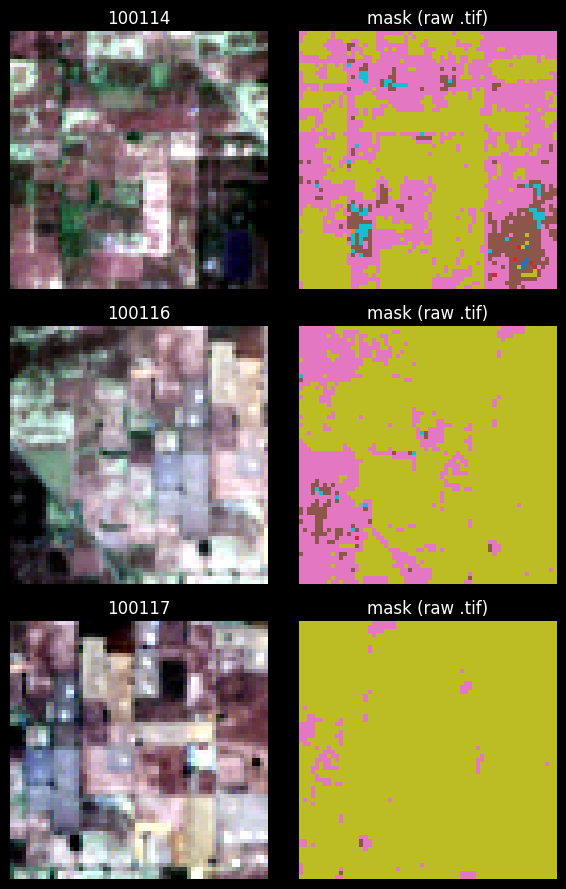

In [3]:
n_show = 3
fig, axes = plt.subplots(n_show, 2, figsize=(6, 3 * n_show))
for i in range(n_show):
    raw_img = Image.open(train_img_paths[i])
    raw_mask = np.array(Image.open(train_mask_paths[i])) - 1

    axes[i, 0].imshow(raw_img)
    axes[i, 0].set_title(Path(train_img_paths[i]).stem)
    axes[i, 0].axis('off')

    axes[i, 1].imshow(raw_mask, cmap='tab10', vmin=0, vmax=N_CLASSES - 1)
    axes[i, 1].set_title('mask (raw .tif)')
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()

## Loading and decoding

Images (PNG) decode natively with `tf.image`. Masks load from pre-converted
`.npy` files via `np.load` inside a `tf.numpy_function`. Images scaled to
[0, 1]; mask labels shifted from 1–7 to 0–6.

**Why `.npy` instead of `.tif`:** PIL TIFF reads inside `tf.numpy_function` are the
primary GPU bottleneck in `train.ipynb` — ~60–100 ms/batch while the GPU forward
pass takes only ~5–15 ms. Pre-converting to `.npy` (numpy binary format) makes each
mask load ~100× faster (~0.3 ms), keeping the GPU at >90% utilisation. Run the
**Mask pre-conversion** cell once before training.

**`tf.clip_by_value(mask, 0, N_CLASSES - 1)`:** A small number of chips contain stray
pixel value 0 (nodata / edge artefact). After the `- 1` shift they become -1, which
crashes `tf.gather` inside the loss. Clamping prevents this.

In [48]:
def _read_mask(path: bytes) -> np.ndarray:
    """Load a pre-converted .npy mask (run the Mask pre-conversion cell once first)."""
    npy_path = path.decode('utf-8').replace('.tif', '.npy')
    return np.load(npy_path)

def load_pair(img_path, mask_path):
    img = tf.io.read_file(img_path)
    img = tf.image.decode_png(img, channels=N_CHANNELS)
    img = tf.cast(img, tf.float32) / 255.0
    img.set_shape([IMG_SIZE, IMG_SIZE, N_CHANNELS])

    mask = tf.numpy_function(_read_mask, [mask_path], tf.uint8)
    mask.set_shape([IMG_SIZE, IMG_SIZE])
    mask = tf.cast(mask, tf.int32) - 1
    # A few chips contain stray 0 (nodata/edge) pixels that become -1 after the
    # shift and crash tf.gather in the loss; clamp them into the valid range.
    mask = tf.clip_by_value(mask, 0, N_CLASSES - 1)
    mask = tf.expand_dims(mask, axis=-1)

    return img, mask

## Augmentation

Light, spectrally-safe augmentation only (flips and 90-degree rotations) —
no color jitter, since hue/brightness shifts would distort the spectral
signal that later needs to transfer to real Sentinel-2 bands.

**Why only geometric augmentation:** Satellite imagery has consistent spectral
signatures (vegetation reflects NIR, water absorbs NIR, etc.). Random brightness or
hue shifts teach the model to ignore those signatures, harming transfer to real S2 scenes.

**`tf.image.rot90(k=...)`:** `k` is drawn uniformly from {0, 1, 2, 3}, giving 0°, 90°,
180°, or 270° rotations. Combined with two independent flip axes, this produces all 8
distinct orientations (the full dihedral group for a square) — effectively 8× data
diversity from each chip without adding any new files.

In [49]:
def augment(img, mask):
    if tf.random.uniform(()) > 0.5:
        img = tf.image.flip_left_right(img)
        mask = tf.image.flip_left_right(mask)
    if tf.random.uniform(()) > 0.5:
        img = tf.image.flip_up_down(img)
        mask = tf.image.flip_up_down(mask)

    k = tf.random.uniform((), minval=0, maxval=4, dtype=tf.int32)
    img = tf.image.rot90(img, k=k)
    mask = tf.image.rot90(mask, k=k)

    return img, mask

## Augmentation check

`augment()` composes an optional horizontal flip with a 90-degree rotation
(`k` = 0-3), which together produce all 8 distinct orientations of the
dihedral group for a square (see the Augmentation section above). Rather
than rely on `augment()`'s random draws — which might not land on every
orientation — enumerate all 8 directly and plot each one against its mask,
to confirm the image and mask stay in sync under every transform.

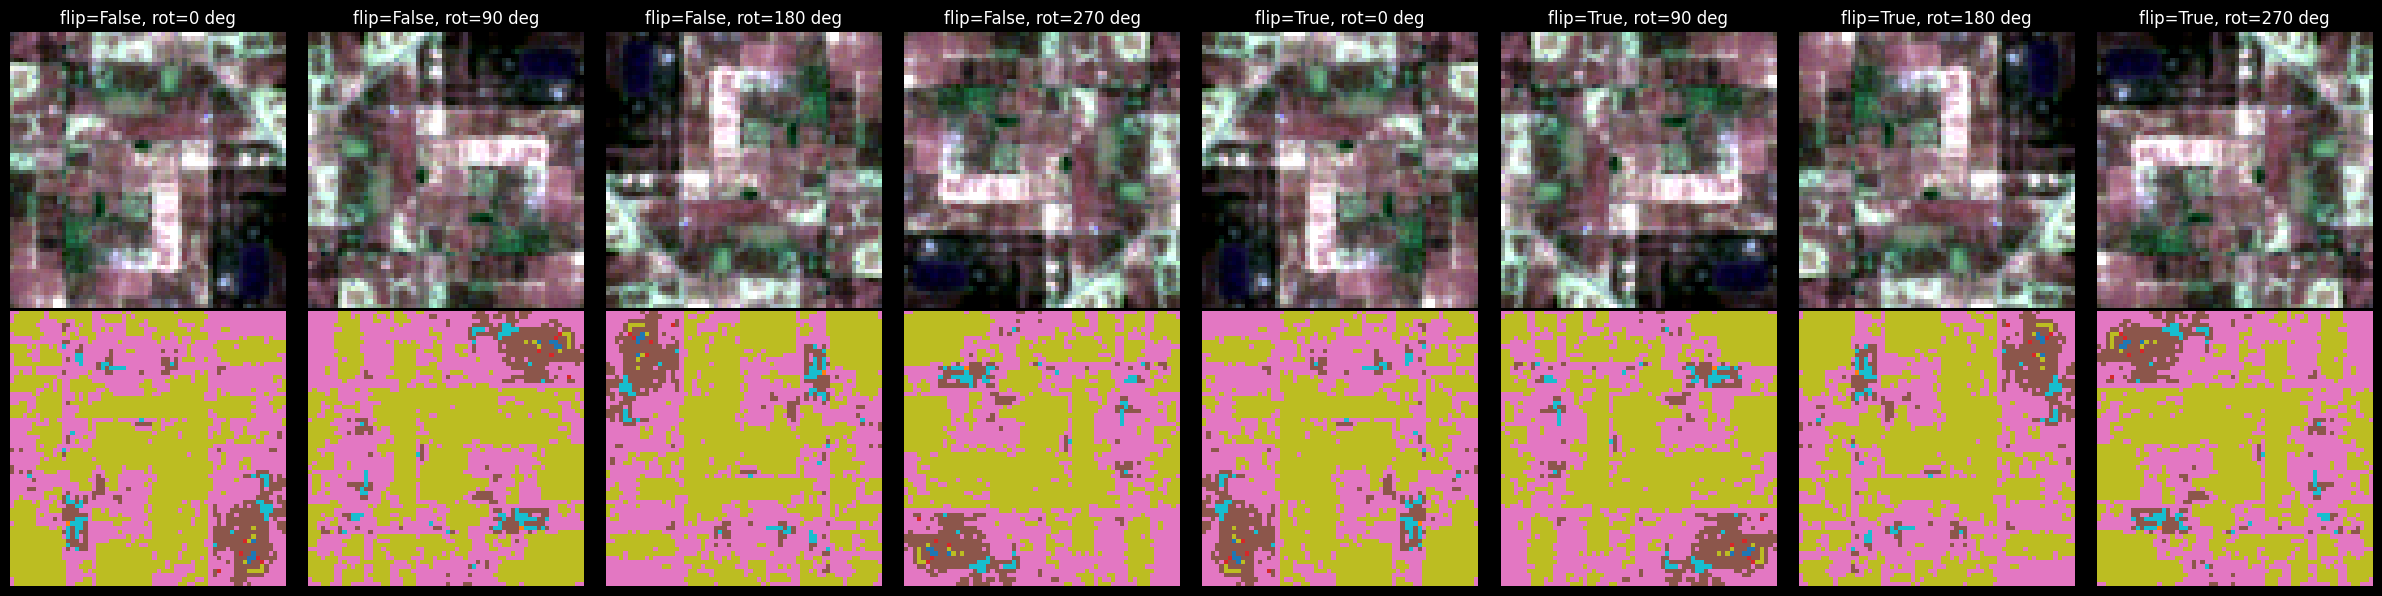

In [4]:
demo_ds = tf.data.Dataset.from_tensor_slices(([train_img_paths[0]], [train_mask_paths[0]]))
demo_ds = demo_ds.map(load_pair)
demo_img, demo_mask = next(iter(demo_ds))

# All 8 orientations = optional flip x 4 rotations (flip_up_down is redundant
# for coverage, since it equals flip_left_right + rot180, already included here).
transforms = [(flip, k) for flip in (False, True) for k in range(4)]

fig, axes = plt.subplots(2, len(transforms), figsize=(3 * len(transforms), 6))
for i, (flip, k) in enumerate(transforms):
    img, mask = demo_img, demo_mask
    if flip:
        img = tf.image.flip_left_right(img)
        mask = tf.image.flip_left_right(mask)
    img = tf.image.rot90(img, k=k)
    mask = tf.image.rot90(mask, k=k)

    axes[0, i].imshow(img)
    axes[0, i].set_title(f'flip={flip}, rot={90 * k}°')
    axes[0, i].axis('off')

    axes[1, i].imshow(mask[..., 0], cmap='tab10', vmin=0, vmax=N_CLASSES - 1)
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

## Building the `tf.data` pipelines

Train, validation, and test sets as `tf.data.Dataset` objects. Augmentation
and shuffling are only applied to the training set.

**Key parameters:**
- `SUBSET = None` — uses the full 149,600 train and 32,079 val chips. Each epoch has 585 batches of 256 (vs. 19 batches in the CPU baseline). Set to `{'train': N, 'val': M}` to cap training during debugging.
- `buffer_size = 2000` — 10× the CPU baseline (200), giving better shuffle randomisation across the large dataset. Uses ~130 MB of RAM at 64×64×3 uint8.
- `num_parallel_calls = tf.data.AUTOTUNE` — TensorFlow chooses how many CPU threads to use for `map` operations. On a GPU, maximising this is critical to avoid data-pipeline starvation.
- `prefetch(tf.data.AUTOTUNE)` — prepares the next batch while the GPU processes the current one, hiding data-loading latency.
- `seed=0` in `subsample` — fixed seed so the same chips are sampled on every run; change the seed to get a different random split.

In [5]:
def make_dataset(img_paths, mask_paths, training=False):
    ds = tf.data.Dataset.from_tensor_slices((img_paths, mask_paths))
    ds = ds.map(load_pair, num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.shuffle(buffer_size=2000)  # 10× CPU baseline for better mixing
        ds = ds.map(augment, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds

# Full dataset — no subsampling on GPU.
SUBSET = None

def subsample(img_paths, mask_paths, n, seed=0):
    if n is None or n >= len(img_paths):
        return img_paths, mask_paths
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(img_paths), size=n, replace=False)
    return [img_paths[i] for i in idx], [mask_paths[i] for i in idx]

train_sub_imgs, train_sub_masks = subsample(train_img_paths, train_mask_paths, SUBSET)
val_sub_imgs, val_sub_masks = subsample(val_img_paths, val_mask_paths, SUBSET)
print(f'training on {len(train_sub_imgs)} / {len(train_img_paths)} train chips, '
      f'{len(val_sub_imgs)} / {len(val_img_paths)} val chips')

train_ds = make_dataset(train_sub_imgs, train_sub_masks, training=True)
val_ds = make_dataset(val_sub_imgs, val_sub_masks)
test_ds = make_dataset(test_img_paths, test_mask_paths)

training on 149600 / 149600 train chips, 32079 / 32079 val chips


## Sanity check

Decode a few batches and plot an image/mask pair to confirm the pipeline
produces correctly-shaped, correctly-aligned data before training.

image batch: (256, 64, 64, 3) <dtype: 'float32'>
mask batch:  (256, 64, 64, 1) <dtype: 'int32'> unique: [0 1 2 3 4 5 6]


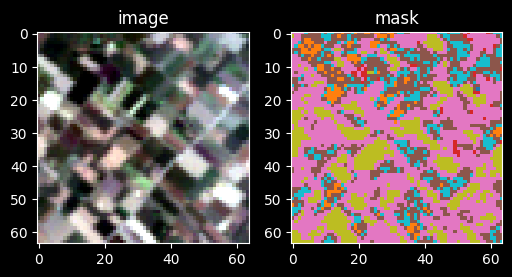

In [6]:
sample_imgs, sample_masks = next(iter(train_ds))
print('image batch:', sample_imgs.shape, sample_imgs.dtype)
print('mask batch: ', sample_masks.shape, sample_masks.dtype, 'unique:', np.unique(sample_masks.numpy()))

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(sample_imgs[0])
axes[0].set_title('image')
axes[1].imshow(sample_masks[0, ..., 0], cmap='tab10', vmin=0, vmax=N_CLASSES - 1)
axes[1].set_title('mask')
plt.show()

## Class weights

A spot check of sampled masks showed heavy class imbalance (agriculture and
built-up dominate pixel counts; water and dense forest are minorities).
Plain cross-entropy biases toward majority classes, so compute inverse-frequency
weights from a sample of training masks to use in the loss.

**Key parameters:**
- `sample_size = 5000` — number of masks read to estimate class frequencies. 5,000 out of 149,600 (~3.3%) gives a stable estimate; increasing it gives marginally better weights at the cost of longer startup.
- `freq + 1e-6` — epsilon prevents division by zero for any class absent from the sample.
- `weights / weights.sum() * n_classes` — rescales weights so they average to 1.0. Without this, the total loss magnitude changes with the number of classes, making the learning rate harder to interpret.
- **Reading the output:** `agriculture: 0.062` means agriculture pixels contribute 0.062× the average weight. `water: 2.823` means water pixels contribute 2.823× — the model is penalised ~45× more per water pixel than per agriculture pixel.

In [7]:
def compute_class_weights(mask_paths, n_classes, sample_size=5000, seed=0):
    rng = np.random.default_rng(seed)
    sample = rng.choice(mask_paths, size=min(sample_size, len(mask_paths)), replace=False)

    counts = np.zeros(n_classes, dtype=np.int64)
    for path in sample:
        labels = np.array(Image.open(path)) - 1
        for c in range(n_classes):
            counts[c] += np.sum(labels == c)

    freq = counts / counts.sum()
    weights = 1.0 / (freq + 1e-6)
    weights = weights / weights.sum() * n_classes
    return weights

class_weights = compute_class_weights(train_mask_paths, N_CLASSES)
for name, w in zip(CLASS_NAMES, class_weights):
    print(f'{name:>15}: {w:.3f}')

          water: 2.823
   dense forest: 2.480
  sparse forest: 0.534
    barren land: 0.284
       built up: 0.108
    agriculture: 0.062
    fallow land: 0.709


## U-Net architecture

A 4-level encoder/decoder (32→64→128→256 filters) with skip connections.
Original draft used a 5-level, 1024-filter U-Net sized for 256×256 inputs;
that's oversized for these 64×64 chips, so it's scaled down here.

**Architecture decisions:**
- `base filters = 32` — feature maps in the first conv block, doubling each level (32→64→128→256). For 64×64 chips, 32 base filters is appropriate — a 5-level 1024-filter network would have more parameters than training pixels.
- **4 encoder levels** — each halves spatial resolution via `MaxPooling2D(2)`. At 64×64 input, 4 levels gives an 8×8 bottleneck. Going deeper would reduce it to 4×4 or 2×2, losing spatial context.
- **Skip connections** (`layers.concatenate`) — pass encoder feature maps directly to the matching decoder level. This preserves fine spatial detail (e.g., class boundaries) lost during downsampling.
- **`Conv2DTranspose(stride=2)`** — learned upsampling. The upsampling kernel weights are trained alongside the rest of the network, generally outperforming fixed `UpSampling2D` for segmentation.
- `activation='softmax'` on output — produces a valid probability distribution across `N_CLASSES` for each pixel. Required by `sparse_categorical_crossentropy`.

In [8]:
def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, activation='relu', padding='same')(x)
    x = layers.Conv2D(filters, 3, activation='relu', padding='same')(x)
    return x

def build_unet(input_size=(IMG_SIZE, IMG_SIZE, N_CHANNELS), n_classes=N_CLASSES):
    inputs = layers.Input(input_size)

    # Encoder
    c1 = conv_block(inputs, 32)
    p1 = layers.MaxPooling2D(2)(c1)

    c2 = conv_block(p1, 64)
    p2 = layers.MaxPooling2D(2)(c2)

    c3 = conv_block(p2, 128)
    p3 = layers.MaxPooling2D(2)(c3)

    c4 = conv_block(p3, 256)

    # Decoder
    u5 = layers.Conv2DTranspose(128, 2, strides=2, padding='same')(c4)
    u5 = layers.concatenate([u5, c3])
    c5 = conv_block(u5, 128)

    u6 = layers.Conv2DTranspose(64, 2, strides=2, padding='same')(c5)
    u6 = layers.concatenate([u6, c2])
    c6 = conv_block(u6, 64)

    u7 = layers.Conv2DTranspose(32, 2, strides=2, padding='same')(c6)
    u7 = layers.concatenate([u7, c1])
    c7 = conv_block(u7, 32)

    outputs = layers.Conv2D(n_classes, 1, activation='softmax')(c7)

    return models.Model(inputs, outputs, name='unet')

model = build_unet()
model.summary()

Model: "unet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 64, 64, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 64, 64,    │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 64, 64,    │      9,248 │ conv2d[0][0]      │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 32, 32,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 32, 32,    │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 32, 32,    │     36,928 │ conv2d_2[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 16, 16,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 16, 16,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 16, 16,    │    147,584 │ conv2d_4[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 8, 8, 128) │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 8, 8, 256) │    295,168 │ max_pooling2d_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 8, 8, 256) │    590,080 │ conv2d_6[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 16, 16,    │    131,200 │ conv2d_7[0][0]    │
│ (Conv2DTranspose)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 16, 16,    │          0 │ conv2d_transpose… │
│ (Concatenate)       │ 256)              │            │ conv2d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 16, 16,    │    295,040 │ concatenate[0][0] │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 16, 16,    │    147,584 │ conv2d_8[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_1  │ (None, 32, 32,    │     32,832 │ conv2d_9[0][0]    │
│ (Conv2DTranspose)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 5,777,399 (22.04 MB)

 Trainable params: 1,925,799 (7.35 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 3,851,600 (14.69 MB)

## Loss function

Weighted sparse categorical cross-entropy (using the class weights computed
above) combined with a Dice loss term, which helps further with the
imbalance by directly optimising class overlap rather than per-pixel likelihood.

**`weighted_sce`:** Standard cross-entropy where each pixel's loss is multiplied by the
weight of its true class. Rare classes (water, dense forest) have high weights, so the
model is penalised more for getting them wrong.

**`dice_loss`:**
- Computes the Sørensen–Dice coefficient per class per batch: `(2 × intersection + ε) / (sum + ε)`.
- Loss = `1 − mean(Dice across classes)`. A perfect prediction gives Dice = 1 and loss = 0.
- `smooth = 1e-6` — prevents 0/0 when a class is absent from an entire batch.
- Dice loss is not affected by class imbalance in the same way cross-entropy is — it measures overlap per class, so a class with 1% of pixels gets equal weight to one with 50%. This makes it complementary to the weighted SCE.

**`combined_loss = weighted_sce + dice_loss`:** Equal weighting. If a minority class (e.g., water) remains low-IoU after a full run, try `weighted_sce + 2 * dice_loss` to push harder on overlap.

In [50]:
class_weights_tensor = tf.constant(class_weights, dtype=tf.float32)

def weighted_sce(y_true, y_pred):
    y_true = tf.cast(tf.squeeze(y_true, axis=-1), tf.int32)
    per_pixel_loss = tf.keras.losses.sparse_categorical_crossentropy(y_true, y_pred)
    weights = tf.gather(class_weights_tensor, y_true)
    return tf.reduce_mean(per_pixel_loss * weights)

def dice_loss(y_true, y_pred, smooth=1e-6):
    y_true = tf.cast(tf.squeeze(y_true, axis=-1), tf.int32)
    y_true_oh = tf.one_hot(y_true, depth=N_CLASSES)
    intersection = tf.reduce_sum(y_true_oh * y_pred, axis=[1, 2])
    union = tf.reduce_sum(y_true_oh + y_pred, axis=[1, 2])
    dice = (2.0 * intersection + smooth) / (union + smooth)
    return 1.0 - tf.reduce_mean(dice)

def combined_loss(y_true, y_pred):
    return weighted_sce(y_true, y_pred) + dice_loss(y_true, y_pred)

## Compiling the model

Optimise with Adam. Track mean IoU rather than pixel accuracy — accuracy is
misleading on an imbalanced segmentation task (a model predicting only
"agriculture" everywhere would still score ~40% accuracy).

**`Adam(learning_rate=1e-3)`:** Adaptive Moment Estimation. Maintains per-parameter
learning rates based on first and second gradient moments. `1e-3` is Adam's canonical
default and a good starting point for most segmentation tasks. The `ReduceLROnPlateau`
callback will automatically reduce this when training plateaus.

**`MeanIoU(num_classes=7, sparse_y_true=True, sparse_y_pred=False)`:**
- `sparse_y_true=True` — ground-truth masks are integer class indices, not one-hot. Avoids expanding a `(B, 64, 64, 1)` tensor to `(B, 64, 64, 7)`.
- `sparse_y_pred=False` — predictions are softmax probabilities `(B, 64, 64, 7)`; MeanIoU internally takes the argmax.
- Mean IoU averages per-class IoU across all 7 classes equally, giving the same weight to rare and common classes — the right metric when minority-class performance matters.

In [ ]:
mean_iou_metric = tf.keras.metrics.MeanIoU(
    num_classes=N_CLASSES,
    sparse_y_true=True,
    sparse_y_pred=False,
    name='mean_iou',
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=combined_loss,
    metrics=[mean_iou_metric],
)

## Callbacks

Stop early and reduce the learning rate when validation mean IoU plateaus;
checkpoint the best weights seen during training.

**`EarlyStopping`:**
- `monitor='val_mean_iou', mode='max'` — watches validation IoU and stops when it stops improving (higher = better, hence `max`).
- `patience=4` — waits 4 epochs of no improvement before stopping. Tight enough to avoid wasting compute, loose enough to survive a temporary plateau after a learning-rate reduction.
- `restore_best_weights=True` — rewinds model weights to the best epoch after stopping, so the saved model is not the last (possibly slightly worse) checkpoint.

**`ReduceLROnPlateau`:**
- `factor=0.5` — halves the learning rate on plateau detection. Starting at 1e-3: first reduction → 5e-4, second → 2.5e-4, etc.
- `patience=2` — reduces LR after just 2 non-improving epochs (half the EarlyStopping patience), giving the model a chance to recover before stopping entirely.
- `min_lr=1e-6` — floor on the learning rate; below this, further reductions have negligible effect.

**`ModelCheckpoint`:**
- `save_best_only=True` — only overwrites the file when `val_mean_iou` improves, so the file always contains the best weights seen so far.
- Saves in Keras v3 format (`.keras`), which bundles architecture, weights, and optimiser state in a single file.

In [ ]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_mean_iou', mode='max', patience=4, restore_best_weights=True,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_mean_iou', mode='max', factor=0.5, patience=2, min_lr=1e-6,
    ),
    tf.keras.callbacks.ModelCheckpoint(
        'unet_sen2_lulc_best_gpu.keras', monitor='val_mean_iou', mode='max', save_best_only=True,
    ),
]

## Training

Train for up to 40 epochs on the full dataset; early stopping (patience 4 on
validation mean IoU) will halt training earlier if improvement stalls.
On a GTX 1660 Ti Max-Q expect ~3–4 min/epoch → ~1.5–2.5 hrs total
(early stopping typically triggers around epoch 25–35).

**`epochs=40`:** Maximum complete passes through the full 149,600-chip training set.
585 batches of 256 per epoch. With the `.npy` mask fix the GPU should run at
>90% utilisation; if it drops back toward 20%, check that the mask conversion
ran completely for all three splits.

**`history`:** Object returned by `model.fit()`. Stores per-epoch metric values:
- `history.history['loss']` / `'val_loss'` — combined loss per epoch
- `history.history['mean_iou']` / `'val_mean_iou'` — mean IoU per epoch
- `history.history['learning_rate']` — LR at each epoch; shows `ReduceLROnPlateau` reductions

**What to expect vs. the CPU baseline (train.ipynb):** The CPU run hit val IoU ~0.24 at
epoch 15 on only 1,200 chips. A full GPU run should comfortably reach 0.40–0.55 val
mean IoU, with water and dense forest IoU recovering from near-zero to 0.15–0.30 once
the model sees enough rare-class chips in each epoch.

In [9]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=callbacks,
)

NOTE: this is a reconstruction from the live kernel's `history` object, recovered
after the original console log/output was accidentally cleared. Per-epoch wall-clock
timings (e.g. "72s") were only ever printed to stdout by Keras during training and were
never stored in `history.history`, so exact per-epoch durations could not be recovered
-- everything below is the exact real metric data from the actual run.

Training ran for 38 epochs (of a maximum 40) before EarlyStopping (patience=4) triggered.

epoch     loss  mean_iou  val_loss  val_mean_iou         lr
-----------------------------------------------------------
    1   1.0534    0.2675    1.0380        0.2647   1.00e-03
    2   0.9543    0.3328    0.9951        0.3177   1.00e-03
    3   0.8995    0.3681    0.9488        0.3275   1.00e-03
    4   0.8620    0.3917    0.9404        0.3362   1.00e-03
    5   0.8352    0.3993    0.8930        0.3649   1.00e-03
    6   0.7678    0.4154    0.8503        0.3746   1.00e-03
    7   0.7336 

## Training curves

Plot loss and mean IoU across epochs to check for overfitting or
under-training before evaluating on the held-out test set.

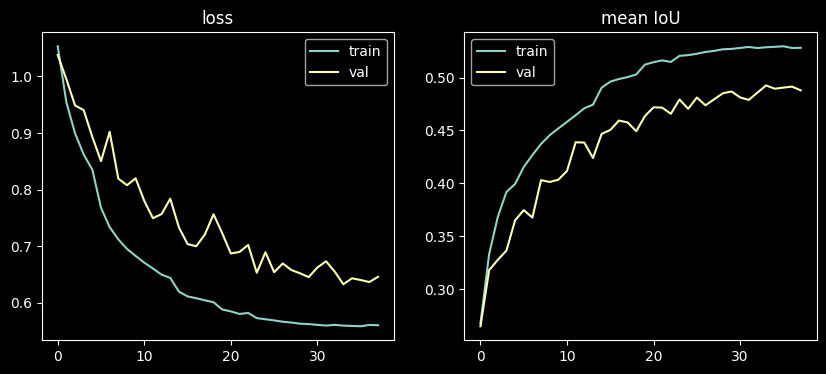

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot(history.history['loss'], label='train')
axes[0].plot(history.history['val_loss'], label='val')
axes[0].set_title('loss')
axes[0].legend()

axes[1].plot(history.history['mean_iou'], label='train')
axes[1].plot(history.history['val_mean_iou'], label='val')
axes[1].set_title('mean IoU')
axes[1].legend()

plt.show()

## Test set evaluation

Evaluate on the untouched test split for the final reported loss/mean IoU.

In [11]:
test_loss, test_mean_iou = model.evaluate(test_ds)
print(f'test loss: {test_loss:.4f}')
print(f'test mean IoU: {test_mean_iou:.4f}')

test loss: 0.6292
test mean IoU: 0.4931


## Per-class IoU

Mean IoU hides which classes the model actually struggles with — recompute
IoU per class over the test set to see if the minority classes (water,
dense forest) are being learned or just ignored.

In [12]:
per_class_iou_metric = tf.keras.metrics.MeanIoU(
    num_classes=N_CLASSES, sparse_y_true=True, sparse_y_pred=False,
)

for images, masks in test_ds:
    preds = model.predict(images, verbose=0)
    per_class_iou_metric.update_state(masks, preds)

cm = per_class_iou_metric.total_cm.numpy()
intersection = np.diag(cm)
union = cm.sum(axis=0) + cm.sum(axis=1) - intersection
iou_per_class = intersection / np.maximum(union, 1e-6)

for name, iou in zip(CLASS_NAMES, iou_per_class):
    print(f'{name:>15}: {iou:.3f}')

          water: 0.243
   dense forest: 0.337
  sparse forest: 0.418
    barren land: 0.485
       built up: 0.623
    agriculture: 0.846
    fallow land: 0.499


## Confusion matrix — why IoU beats accuracy here

Pixel accuracy divides all correct pixels by all pixels. Since agriculture and
built-up together make up most of the pixels in this dataset, a model can score
high overall accuracy just by getting the common classes right, even while
completely failing on rare classes like water and dense forest.

IoU (`intersection / union`) is computed *per class*, then averaged. It
penalises missed pixels (false negatives) and extra pixels (false positives)
equally, regardless of how common that class is — a class with 1% of pixels
counts exactly as much toward mean IoU as a class with 40% of pixels. That's
why mean IoU can look much lower than accuracy on an imbalanced dataset like
this one, and why it's the more honest metric for judging whether the model
actually learned the rare classes.

The `cm` confusion matrix computed above makes this concrete: the raw counts
are dominated by whichever classes are common, but the row-normalised version
(each row divided by its total — i.e. per-class recall) shows exactly where
each class's pixels are actually ending up.

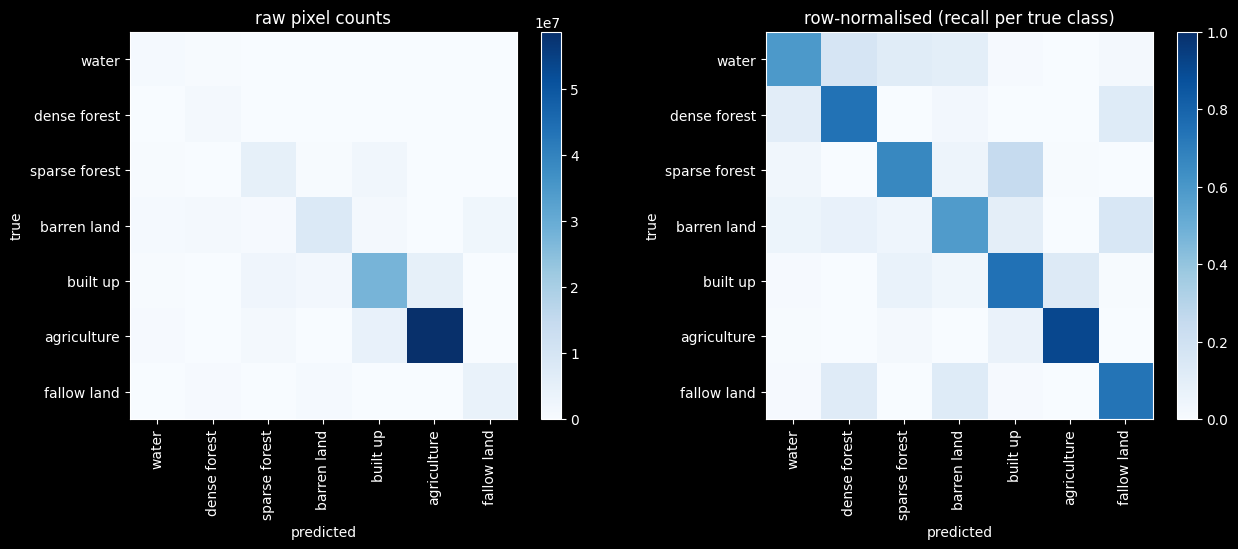

pixel accuracy (this model):                          0.802
mean IoU (this model):                                 0.493
"always predict agriculture" baseline accuracy: 0.490
"always predict agriculture" baseline mean IoU: 0.070


In [13]:
cm_normalized = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, data, title, vmax in [
    (axes[0], cm, 'raw pixel counts', cm.max()),
    (axes[1], cm_normalized, 'row-normalised (recall per true class)', 1.0),
]:
    im = ax.imshow(data, cmap='Blues', vmin=0, vmax=vmax)
    ax.set_title(title)
    ax.set_xlabel('predicted')
    ax.set_ylabel('true')
    ax.set_xticks(range(N_CLASSES))
    ax.set_yticks(range(N_CLASSES))
    ax.set_xticklabels(CLASS_NAMES, rotation=90)
    ax.set_yticklabels(CLASS_NAMES)
    plt.colorbar(im, ax=ax, fraction=0.046)

plt.tight_layout()
plt.show()

# Compare the model's real metrics against a trivial "always predict the
# majority class" baseline, to show how misleading accuracy alone would be.
pixel_accuracy = np.trace(cm) / cm.sum()
mean_iou = iou_per_class.mean()

row_totals = cm.sum(axis=1)
majority_idx = np.argmax(row_totals)
majority_accuracy = row_totals[majority_idx] / cm.sum()

baseline_cm = np.zeros_like(cm)
baseline_cm[:, majority_idx] = row_totals  # every pixel predicted as the majority class
baseline_intersection = np.diag(baseline_cm)
baseline_union = baseline_cm.sum(axis=0) + baseline_cm.sum(axis=1) - baseline_intersection
with np.errstate(divide='ignore', invalid='ignore'):
    baseline_iou = np.where(baseline_union > 0, baseline_intersection / baseline_union, 0.0)

print(f'pixel accuracy (this model):                          {pixel_accuracy:.3f}')
print(f'mean IoU (this model):                                 {mean_iou:.3f}')
print(f'"always predict {CLASS_NAMES[majority_idx]}" baseline accuracy: {majority_accuracy:.3f}')
print(f'"always predict {CLASS_NAMES[majority_idx]}" baseline mean IoU: {baseline_iou.mean():.3f}')

## Interpreting the per-class IoU values

Each class's IoU depends on both how well the model learned it and how much
signal it saw during training (governed by the `class_weights` computed
earlier). The cell below ranks classes from weakest to strongest IoU and
checks whether low IoU lines up with high class weight (i.e. rarity):

- **Negative correlation** (rarer classes score lower IoU) means the weighted
  loss + Dice term are pulling in the right direction but haven't fully closed
  the imbalance gap — more epochs, a higher Dice weight, or more aggressive
  class weighting would help.
- **Weak or no correlation** means some classes are weak for reasons other
  than rarity — most likely visual ambiguity with a neighbouring class (check
  the confusion matrix above to see which class it's being confused with).

In [14]:
order = np.argsort(iou_per_class)
print('classes ranked weakest to strongest IoU:')
for idx in order:
    print(f'  {CLASS_NAMES[idx]:>15}: IoU={iou_per_class[idx]:.3f}, class weight={class_weights[idx]:.2f}')

worst_idx, best_idx = order[0], order[-1]
corr = np.corrcoef(class_weights, iou_per_class)[0, 1]

print(f'\nweakest class:   {CLASS_NAMES[worst_idx]} (IoU={iou_per_class[worst_idx]:.3f})')
print(f'strongest class: {CLASS_NAMES[best_idx]} (IoU={iou_per_class[best_idx]:.3f})')
print(f'correlation between class weight (rarity) and IoU: {corr:.2f}')

if corr < -0.3:
    print('Negative correlation: rarer classes tend to have lower IoU — the imbalance')
    print('is only partly offset by the weighted loss and Dice term.')
elif corr > 0.3:
    print('Positive correlation is unexpected here — rarity is not the main driver of IoU.')
else:
    print('Weak correlation: IoU is not simply explained by class rarity — some classes')
    print('are likely weak due to visual ambiguity with a neighbouring class instead')
    print('(see which class they get confused with in the confusion matrix above).')

classes ranked weakest to strongest IoU:
            water: IoU=0.243, class weight=2.82
     dense forest: IoU=0.337, class weight=2.48
    sparse forest: IoU=0.418, class weight=0.53
      barren land: IoU=0.485, class weight=0.28
      fallow land: IoU=0.499, class weight=0.71
         built up: IoU=0.623, class weight=0.11
      agriculture: IoU=0.846, class weight=0.06

weakest class:   water (IoU=0.243)
strongest class: agriculture (IoU=0.846)
correlation between class weight (rarity) and IoU: -0.80
Negative correlation: rarer classes tend to have lower IoU -- the imbalance
is only partly offset by the weighted loss and Dice term.


## Visual check

Plot a few test images alongside their ground-truth and predicted masks for
a qualitative sense of where the model succeeds or fails.

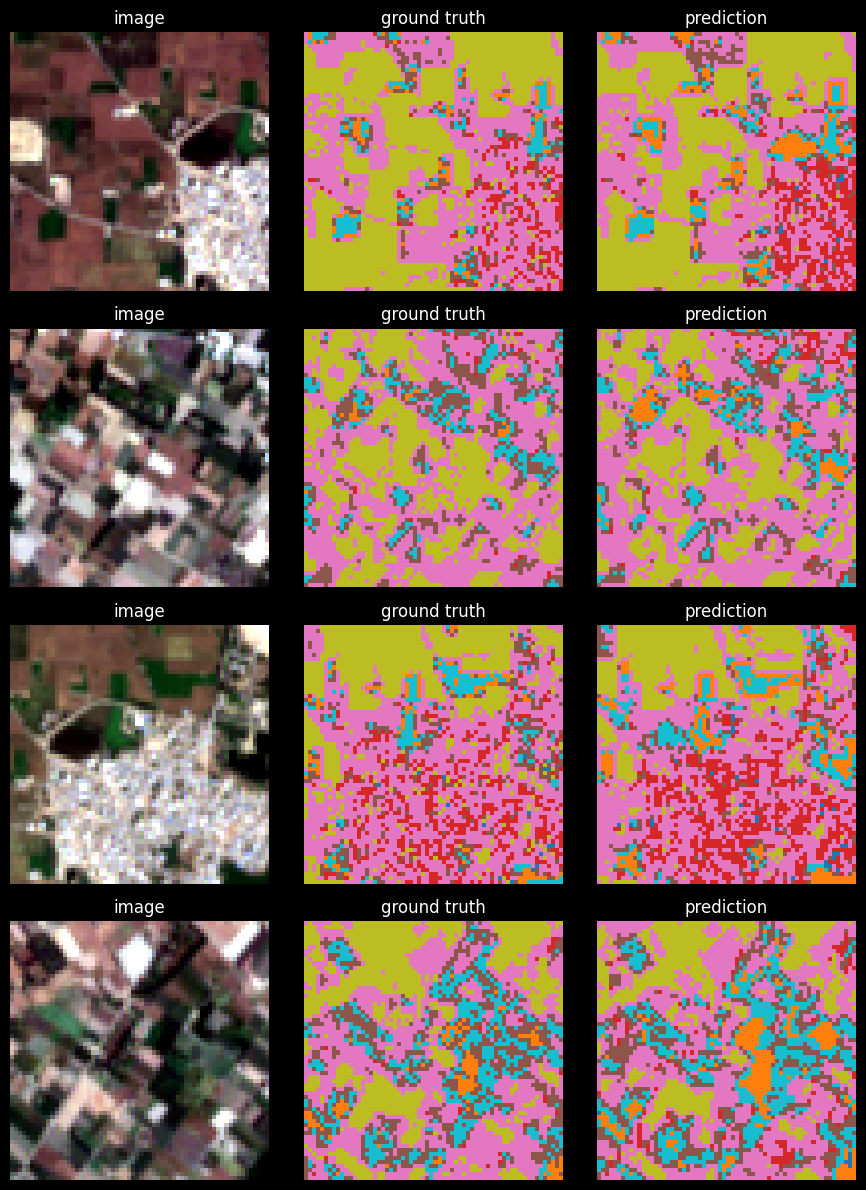

In [15]:
images, masks = next(iter(test_ds))
preds = model.predict(images, verbose=0)
pred_classes = np.argmax(preds, axis=-1)

n_show = 4
fig, axes = plt.subplots(n_show, 3, figsize=(9, 3 * n_show))
for i in range(n_show):
    axes[i, 0].imshow(images[i])
    axes[i, 0].set_title('image')
    axes[i, 1].imshow(masks[i, ..., 0], cmap='tab10', vmin=0, vmax=N_CLASSES - 1)
    axes[i, 1].set_title('ground truth')
    axes[i, 2].imshow(pred_classes[i], cmap='tab10', vmin=0, vmax=N_CLASSES - 1)
    axes[i, 2].set_title('prediction')
    for ax in axes[i]:
        ax.axis('off')

plt.tight_layout()
plt.show()

## Interpreting the ground-truth vs prediction grid

Beyond the aggregate metrics, it's worth looking at where errors happen
spatially. Look for:

- **Boundary blur** — predictions that get the coarse land-cover right but
  blur or round off sharp edges between classes (a common U-Net artefact at
  64×64 resolution with only 3 downsampling steps).
- **Minority-class dropout** — chips where the ground truth has a patch of a
  rare class (e.g. water) that the prediction misses entirely and instead
  extends a neighbouring majority class over it. This is exactly the failure
  mode a high pixel-accuracy score can hide, but low per-class IoU exposes.
- **Confusion between visually similar classes** — e.g. sparse vs dense
  forest, or barren land vs fallow land, which look similar in colour and
  texture at this resolution.

The cell below quantifies the four specific chips plotted above, so you can
match what you see visually to a number.

In [16]:
print('per-sample metrics for the four chips plotted above:')
for i in range(n_show):
    true_flat = masks[i, ..., 0].numpy().flatten()
    pred_flat = pred_classes[i].flatten()

    acc = (true_flat == pred_flat).mean()

    sample_cm = tf.math.confusion_matrix(true_flat, pred_flat, num_classes=N_CLASSES).numpy()
    intersection = np.diag(sample_cm)
    union = sample_cm.sum(axis=0) + sample_cm.sum(axis=1) - intersection
    classes_present = union > 0
    sample_mean_iou = (intersection[classes_present] / union[classes_present]).mean()

    print(f'  sample {i}: pixel accuracy={acc:.3f}, mean IoU (classes present)={sample_mean_iou:.3f}')

per-sample metrics for the four chips plotted above:
  sample 0: pixel accuracy=0.830, mean IoU (classes present)=0.508
  sample 1: pixel accuracy=0.862, mean IoU (classes present)=0.492
  sample 2: pixel accuracy=0.774, mean IoU (classes present)=0.497
  sample 3: pixel accuracy=0.750, mean IoU (classes present)=0.445
